# Assignment 3: Generative Adversarial Networks

Name: He Xiao  
UNI: hx2425  
GitHub repository: [HotcatX/API-test](https://github.com/HotcatX/API-test)

This submission implements the specified PyTorch GAN, trains it on MNIST,
adds handwritten-digit generation to the existing FastAPI application,
and answers the seven theoretical questions.

Running this notebook reads the saved training artifacts and performs small
verification and inference checks. Training and dataset download are separate
commands. Use the project's `API-test (.venv)` kernel.

## Part I. Practice: GAN Architecture

The generator takes 100-dimensional standard-normal noise and returns a
grayscale image of shape `(N, 1, 28, 28)` with pixel values in `[-1, 1]`.
The discriminator maps each image to one real-image probability.
This is an unconditional GAN: there is no digit-label input.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import inspect
import json
import math
import os
import sys
import warnings

import torch
from torch import nn
from IPython.display import Markdown, display
from PIL import Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(path for path in candidates
            if (path / "app/gan_model.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from app.gan_model import ARCHITECTURE_VERSION, LATENT_DIM, Generator, Discriminator

torch.set_num_threads(min(2, torch.get_num_threads()))
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Using project .venv:", Path(sys.prefix).resolve() == (ROOT / ".venv").resolve())

Python: 3.12.14
PyTorch: 2.8.0
Using project .venv: True


### Generator implementation

The following is the actual class imported by both the training script and
API. The fully connected layer is reshaped directly, as specified; the first
transposed convolution is followed by BatchNorm and ReLU, and the final
transposed convolution is followed by Tanh.

In [2]:
print(inspect.getsource(Generator))

class Generator(nn.Module):
    """Unconditional generator: (B, 100) -> (B, 1, 28, 28)."""

    def __init__(self) -> None:
        super().__init__()
        self.fc = nn.Linear(LATENT_DIM, 7 * 7 * 128)
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, noise: torch.Tensor) -> torch.Tensor:
        features = self.fc(noise).reshape(-1, 128, 7, 7)
        return self.layers(features)



### Discriminator implementation

Both convolutional blocks use LeakyReLU with negative slope 0.2. BatchNorm
follows the second convolution. A sigmoid converts the final linear output
into a probability, so the training loss is `BCELoss`.

In [3]:
print(inspect.getsource(Discriminator))

class Discriminator(nn.Module):
    """Discriminator: (B, 1, 28, 28) -> (B, 1) real-image probability."""

    def __init__(self) -> None:
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(7 * 7 * 128, 1),
            nn.Sigmoid(),
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.layers(images)



### Shapes and parameter counts

The generator's transposed convolutions give
$(7-1)2-2+4=14$ and $(14-1)2-2+4=28$.
The discriminator reduces 28 to 14 and then to 7. All linear and convolution
layers include biases. BatchNorm has a learned scale and shift per channel;
its running statistics are buffers, not trainable parameters.

| Generator layer | Output shape | Trainable parameters |
| --- | --- | ---: |
| Linear and reshape | `(N, 128, 7, 7)` | 633,472 |
| ConvTranspose2d, 128 → 64, 4 × 4, stride 2, padding 1 | `(N, 64, 14, 14)` | 131,136 |
| BatchNorm2d and ReLU | `(N, 64, 14, 14)` | 128 |
| ConvTranspose2d, 64 → 1, 4 × 4, stride 2, padding 1; Tanh | `(N, 1, 28, 28)` | 1,025 |
| Total | | 765,761 |

| Discriminator layer | Output shape | Trainable parameters |
| --- | --- | ---: |
| Conv2d, 1 → 64, 4 × 4, stride 2, padding 1; LeakyReLU | `(N, 64, 14, 14)` | 1,088 |
| Conv2d, 64 → 128, 4 × 4, stride 2, padding 1 | `(N, 128, 7, 7)` | 131,200 |
| BatchNorm2d and LeakyReLU | `(N, 128, 7, 7)` | 256 |
| Flatten; Linear, 6272 → 1; Sigmoid | `(N, 1)` | 6,273 |
| Total | | 138,817 |

In [4]:
# These untrained instances are used only for architecture checks.
generator = Generator().eval()
discriminator = Discriminator().eval()
noise = torch.randn(2, LATENT_DIM, generator=torch.Generator().manual_seed(42))
with torch.inference_mode():
    generated = generator(noise)
    probabilities = discriminator(generated)
assert generated.shape == (2, 1, 28, 28)
assert probabilities.shape == (2, 1)
assert torch.isfinite(generated).all() and generated.abs().max() <= 1
assert torch.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()
generator_parameters = sum(p.numel() for p in generator.parameters())
discriminator_parameters = sum(p.numel() for p in discriminator.parameters())
assert generator_parameters == 765_761
assert discriminator_parameters == 138_817
print("Generator output:", tuple(generated.shape))
print("Discriminator output:", tuple(probabilities.shape))
print(f"Trainable parameters: G={generator_parameters:,}; D={discriminator_parameters:,}")

Generator output: (2, 1, 28, 28)
Discriminator output: (2, 1)
Trainable parameters: G=765,761; D=138,817


## Part II. Practice: Training and API Deployment

### Data and training objective

Training uses all 60,000 images in MNIST's official training split. Each
28 × 28 grayscale image is scaled by `uint8 / 127.5 - 1`, giving `[-1, 1]`
values that match the generator's Tanh output. The integer labels are not
used. No MNIST test images are used for training.

With real images $x$, independent noise $z\sim\mathcal{N}(0,I)$, and
discriminator probability $D(\cdot)$, the losses minimized are

$$L_D=-\mathbb{E}_x[\log D(x)]
      -\mathbb{E}_z[\log(1-D(G(z)))],$$

$$L_G=-\mathbb{E}_z[\log D(G(z))].$$

The discriminator uses `BCE(D(real), 1) + BCE(D(fake.detach()), 0)`.
Detaching fake images prevents its update from changing the generator.
The generator uses the non-saturating objective `BCE(D(fake), 1)` while the
discriminator's parameters are frozen; gradients still pass through the
discriminator to the generator. Both networks use Adam. Full training
code is in `scripts/train_mnist_gan.py`.

### Recorded configuration and checkpoint

The following cells read the actual completed training record, verify the
checkpoint's SHA-256 hash, and load its saved weights on the CPU. Evaluation
mode makes BatchNorm use its saved running statistics during inference.

In [5]:
metrics = json.loads((ROOT / "assignment3/training_metrics.json").read_text())
history = json.loads((ROOT / "assignment3/training_history.json").read_text())
checkpoint_path = ROOT / "models/mnist_gan.pt"
actual_sha256 = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
assert actual_sha256 == metrics["checkpoint_sha256"]
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
assert metrics["train_count"] == checkpoint["train_count"] == 60_000
assert metrics["conditional"] is checkpoint["conditional"] is False
assert metrics["latent_dim"] == checkpoint["latent_dim"] == LATENT_DIM == 100
assert checkpoint["architecture_version"] == ARCHITECTURE_VERSION
assert len(history) == checkpoint["epochs"] == metrics["epochs"]
assert all(row["images_seen"] == 60_000 for row in history)
assert metrics["generator_parameters"] == generator_parameters
assert metrics["discriminator_parameters"] == discriminator_parameters
generator.load_state_dict(checkpoint["generator_state_dict"], strict=True)
discriminator.load_state_dict(checkpoint["discriminator_state_dict"], strict=True)
generator.eval()
discriminator.eval()
settings = [
    ("Training images", metrics["train_count"]),
    ("Epochs", metrics["epochs"]),
    ("Training seed", metrics["seed"]),
    ("Batch size", metrics["batch_size"]),
    ("Optimizer", "Adam"),
    ("Learning rate", metrics["learning_rate"]),
    ("Adam betas", metrics["adam_betas"]),
    ("Training device", metrics["training_device"]),
    ("Training time (seconds)", round(metrics["training_seconds"], 2)),
]
table = ["| Setting | Recorded value |", "| --- | --- |"]
table.extend(f"| {name} | {value} |" for name, value in settings)
display(Markdown("\n".join(table)))
print("Checkpoint SHA-256:", actual_sha256)

| Setting | Recorded value |
| --- | --- |
| Training images | 60000 |
| Epochs | 20 |
| Training seed | 42 |
| Batch size | 128 |
| Optimizer | Adam |
| Learning rate | 0.0002 |
| Adam betas | [0.5, 0.999] |
| Training device | mps |
| Training time (seconds) | 198.92 |

Checkpoint SHA-256: 5854d759b692c4887fb54e514ab3e676c60941c4a6e5606e6d3dc172b153f3ef


### Training losses and fixed samples

These adversarial losses are training diagnostics, not classification
accuracy or a monotonic image-quality score. The compact table samples the
recorded epochs; the complete history is in `assignment3/training_history.json`.
The grid contains the first 64 draws from the fixed noise seed recorded below,
rather than images selected for their appearance. It provides a qualitative
inspection, without claiming a measured FID score or complete digit coverage.

| Epoch | D loss | G loss | Mean D(real) | Mean D(fake), before G update |
| ---: | ---: | ---: | ---: | ---: |
| 1 | 0.4766 | 2.5318 | 0.8325 | 0.1755 |
| 5 | 0.5844 | 1.9275 | 0.7842 | 0.2167 |
| 10 | 0.4889 | 2.3183 | 0.8232 | 0.1771 |
| 15 | 0.4557 | 2.6075 | 0.8398 | 0.1597 |
| 20 | 0.4041 | 2.8145 | 0.8583 | 0.1413 |

Fixed-grid noise seed: 2026
Fixed-grid image count: 64
First 64 noise draws using fixed CPU seed 2026; no outcome-based selection.


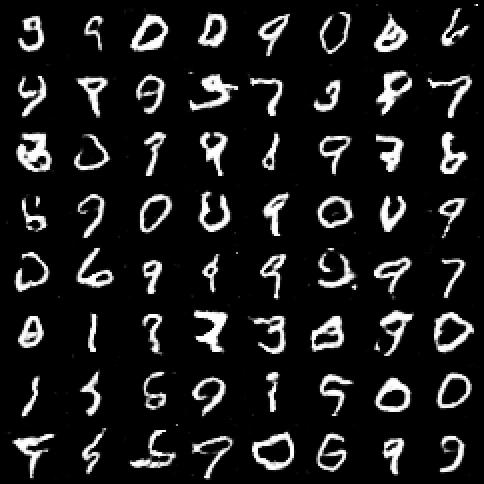

In [6]:
show_epochs = {1, 5, 10, 15, metrics["epochs"]}
table = [
    "| Epoch | D loss | G loss | Mean D(real) | Mean D(fake), before G update |",
    "| ---: | ---: | ---: | ---: | ---: |",
]
for row in history:
    if row["epoch"] in show_epochs:
        table.append(
            f"| {row['epoch']} | {row['discriminator_loss']:.4f} | "
            f"{row['generator_loss']:.4f} | {row['mean_d_real']:.4f} | "
            f"{row['mean_d_fake_before_g_update']:.4f} |"
        )
display(Markdown("\n".join(table)))
print("Fixed-grid noise seed:", metrics["sample_grid_noise_seed"])
print("Fixed-grid image count:", metrics["sample_grid_count"])
print(metrics["sample_selection"])
with Image.open(ROOT / "assignment3/generated_samples.png") as image:
    samples = image.copy()
display(samples.resize((samples.width * 2, samples.height * 2), Image.Resampling.NEAREST))

### FastAPI interface and live in-process checks

`GET /generate-digit?seed=42` returns one 28 × 28 grayscale PNG.
`POST /generate-digits` accepts `{"count": 16, "seed": 42}` and returns a
PNG grid. `count` can be 1-64; `seed` can be 0-4294967295 or omitted for
random noise. The `X-Seed` header records the seed used. A seed controls
the noise and does not request a particular digit label.

The API uses the saved generator in evaluation mode and converts Tanh
outputs back to grayscale pixels. It does not train or download anything
while handling requests. Invalid inputs return HTTP 422; a missing or
incompatible checkpoint returns HTTP 503. Generated digits can be ambiguous.

The existing text, embedding, and CIFAR-10 classification routes remain
available. The checks below exercise the real FastAPI routes and checkpoint
through `TestClient`; they do not require a separately running web server.

GET /generate-digit: HTTP 200; 28 x 28 grayscale PNG
POST /generate-digits: HTTP 200; 16-image grid; seed 42
Same seed and count reproduce identical PNG bytes: True
Invalid count: HTTP 422


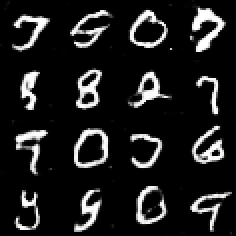

In [7]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message="Using `httpx` with `starlette.testclient` is deprecated.*"
    )
    from fastapi.testclient import TestClient
from app.main import app
from app.digit_generator import load_generator

configured_path = os.environ.get("GAN_MODEL_PATH")
if configured_path:
    assert Path(configured_path).resolve() == checkpoint_path.resolve(), (
        "Unset GAN_MODEL_PATH to verify the submitted checkpoint."
    )
load_generator.cache_clear()
with TestClient(app) as client:
    single_response = client.get("/generate-digit", params={"seed": 42})
    grid_response = client.post("/generate-digits", json={"count": 16, "seed": 42})
    repeated = client.post("/generate-digits", json={"count": 16, "seed": 42})
    invalid = client.post("/generate-digits", json={"count": 0, "seed": 42})
for response in [single_response, grid_response, repeated]:
    assert response.status_code == 200, response.text
    assert response.headers["content-type"] == "image/png"
    assert response.headers["x-seed"] == "42"
assert grid_response.content == repeated.content
assert invalid.status_code == 422
with Image.open(BytesIO(single_response.content)) as image:
    assert image.size == (28, 28) and image.mode == "L"
with Image.open(BytesIO(grid_response.content)) as image:
    api_grid = image.copy()
assert api_grid.size == (118, 118) and api_grid.mode == "L"
print("GET /generate-digit: HTTP 200; 28 x 28 grayscale PNG")
print("POST /generate-digits: HTTP 200; 16-image grid; seed 42")
print("Same seed and count reproduce identical PNG bytes:", grid_response.content == repeated.content)
print("Invalid count: HTTP", invalid.status_code)
display(api_grid.resize((236, 236), Image.Resampling.NEAREST))

### Running the API locally and with Docker

Run these commands from the repository root:

```bash
uv sync --locked --group dev --group notebook
uv run --group notebook python -m ipykernel install --sys-prefix \
  --name api-test --display-name "API-test (.venv)"
uv run uvicorn app.main:app --host 0.0.0.0 --port 8000
```

Swagger documentation is available at `http://localhost:8000/docs`.
In a second terminal, save generated PNG images:

```bash
curl "http://localhost:8000/generate-digit?seed=42" -o digit.png
curl -X POST "http://localhost:8000/generate-digits" \
  -H "Content-Type: application/json" \
  -d '{"count":16,"seed":42}' -o digits.png
```

Build and start the Docker deployment with:

```bash
docker build -t api-test:assignment3 .
docker run --rm -p 8000:80 api-test:assignment3
```

The image includes the trained weights. The same curl requests work against
the container. The repository's `.github/workflows/verify.yml` configures
automated tests, a Docker build, and HTTP smoke checks. Actual recorded
verification status is shown in the following cell.

In [8]:
verification_path = ROOT / "assignment3/verification.json"
if verification_path.is_file():
    verification = json.loads(verification_path.read_text())
    rows = [
        ("Local automated tests", str(verification.get("local_tests_passed", "Not recorded")) + " passed"),
        ("Local HTTP checks", verification.get("local_http_validation", "Not recorded")),
        ("Docker build and HTTP checks", verification.get("docker_validation", "Not recorded")),
        ("Linux CI tests", verification.get("ci_tests", "Not recorded")),
        ("Verified runtime commit", verification.get("tested_commit", "Not recorded")[:12]),
    ]
    table = ["| Check | Result |", "| --- | --- |"]
    table.extend(f"| {name} | {result} |" for name, result in rows)
    display(Markdown("\n".join(table)))
    if verification.get("workflow_url"):
        display(Markdown("[Verified GitHub Actions run](" + verification["workflow_url"] + ")"))
else:
    print("Additional test/deployment verification has not been recorded in verification.json.")

| Check | Result |
| --- | --- |
| Local automated tests | 96 passed |
| Local HTTP checks | passed |
| Docker build and HTTP checks | passed |
| Linux CI tests | passed |
| Verified runtime commit | 44679c033307 |

[Verified GitHub Actions run](https://github.com/HotcatX/API-test/actions/runs/41283477512)

### Reproducing training and checks

Training is an explicit separate operation. The following command uses the
recorded hyperparameters, downloads MNIST into the ignored `data/` directory
if needed, and overwrites the GAN checkpoint and training artifacts:

```bash
uv run python scripts/train_mnist_gan.py \
  --epochs 20 --batch-size 128 \
  --learning-rate 0.0002 --seed 42
```

Seeds fix the intended random choices, but device and library differences
can still change floating-point results. To run automated tests without
retraining:

```bash
uv run --group dev pytest -q
```

## Part III. Theory: Building Blocks of GANs

Each answer below shows the formula and substitutions used. The final code
cell independently verifies the output sizes and BatchNorm arithmetic.

### Question 1

Given an 8 × 8 input, find the output size of a transposed convolution with a 4 × 4 kernel, stride 2, padding 1, and output padding 1. Show the calculation.

For one spatial dimension, with dilation equal to 1,

$$
O=(I-1)S-2P+K+OP.
$$

Substituting the given values,

$$
O=(8-1)(2)-2(1)+4+1=14-2+4+1=17.
$$

The same calculation applies to height and width, so the output spatial size is 17 × 17. The number of output channels depends on the number of filters, which is not specified.

### Question 2

How does the output size change if the stride increases from 2 to 3 while everything else stays fixed?

Using the input, kernel, padding, and output padding from Question 1,

$$
O_{S=3}=(8-1)(3)-2(1)+4+1=21-2+4+1=24.
$$

The output changes from 17 × 17 to 24 × 24. Each spatial dimension increases by

$$
\Delta O=(I-1)\Delta S=(8-1)(3-2)=7.
$$

### Question 3

Write the output-size formula for a 2D transposed convolution in terms of input size I, kernel size K, stride S, padding P, and output padding OP.

Assuming dilation 1, the formula for each spatial dimension is

$$
O=(I-1)S-2P+K+OP.
$$

For a rectangular input or different height/width settings, apply it separately:

$$
H_{out}=(H_{in}-1)S_h-2P_h+K_h+OP_h,
$$

$$
W_{out}=(W_{in}-1)S_w-2P_w+K_w+OP_w.
$$

More generally, with dilation D, replace K by the effective kernel size D(K - 1) + 1:

$$
O=(I-1)S-2P+D(K-1)+OP+1.
$$

This is the shape convention used by [PyTorch ConvTranspose2d](https://docs.pytorch.org/docs/2.8/generated/torch.nn.ConvTranspose2d.html).

### Question 4

Give one kernel-size and stride configuration that upsamples a 16 × 16 feature map to 32 × 32 using a transposed convolution with no padding.

Choose a 2 × 2 kernel and stride 2, with padding 0, output padding 0, and dilation 1. Then

$$
O=(16-1)(2)-2(0)+2+0=30+2=32.
$$

Therefore, kernel_size=2 and stride=2 give the required 32 × 32 output.

### Question 5

For the mini-batch [6, 8, 10, 6], compute BatchNorm's normalized output without the learned scale and shift parameters gamma and beta.

The batch mean is

$$
\mu_B=\frac{6+8+10+6}{4}=\frac{30}{4}=7.5.
$$

Batch normalization uses the mini-batch variance with denominator 4:

$$
\sigma_B^2=\frac{(6-7.5)^2+(8-7.5)^2+(10-7.5)^2+(6-7.5)^2}{4}
$$

$$
=\frac{2.25+0.25+6.25+2.25}{4}=\frac{11}{4}=2.75.
$$

Thus the standard deviation is

$$
\sigma_B=\sqrt{2.75}=\frac{\sqrt{11}}{2}\approx1.658312.
$$

For the requested ideal zero-mean, unit-variance calculation, take epsilon to be 0. Normalize each value using

$$
\hat{x}_i=\frac{x_i-\mu_B}{\sigma_B}.
$$

The normalized output, in the original order, is

$$
\hat{x}=\left[\frac{-3}{\sqrt{11}},\frac{1}{\sqrt{11}},\frac{5}{\sqrt{11}},\frac{-3}{\sqrt{11}}\right]
$$

$$
\approx[-0.904534,\;0.301511,\;1.507557,\;-0.904534].
$$

The normalized mean is (-3 + 1 + 5 - 3)/(4 sqrt(11)) = 0. Its batch variance is

$$
\frac{1}{4}\left(\frac{9+1+25+9}{11}\right)=\frac{44}{44}=1.
$$

In practice, BatchNorm divides by sqrt(variance + epsilon) for numerical stability, so a positive epsilon makes the variance slightly less than 1. PyTorch uses the denominator-N variance for the training forward pass; its running-variance update uses an unbiased estimate instead. These are distinct operations. See [PyTorch BatchNorm2d](https://docs.pytorch.org/docs/2.8/generated/torch.nn.BatchNorm2d.html).

### Question 6

What is the key mathematical difference between ReLU and LeakyReLU? Give their formulas.

ReLU maps every negative input to zero:

$$
\operatorname{ReLU}(x)=\max(0,x)=
\begin{cases}
x, & x\geq0,\\
0, & x<0.
\end{cases}
$$

LeakyReLU uses a small positive slope alpha on the negative side:

$$
\operatorname{LeakyReLU}(x)=
\begin{cases}
x, & x\geq0,\\
\alpha x, & x<0,
\end{cases}
\qquad 0<\alpha<1.
$$

The key difference is the slope for x < 0: ReLU's slope is 0, while LeakyReLU's slope is alpha. The specified discriminator uses alpha = 0.2, so an input of -5 produces 0 under ReLU and -1 under LeakyReLU. The formula follows [PyTorch LeakyReLU](https://docs.pytorch.org/docs/2.8/generated/torch.nn.LeakyReLU.html).

### Question 7

Why might LeakyReLU be preferred over ReLU in deep networks?

For negative pre-activation x, ReLU has derivative 0. By the chain rule,

$$
\frac{\partial L}{\partial x}=\frac{\partial L}{\partial y}\frac{\partial y}{\partial x}.
$$

If a ReLU unit receives negative inputs for all relevant training examples, its activation derivative blocks the gradient through that unit. Its incoming weights may then stop receiving useful updates: the dying-ReLU problem.

LeakyReLU has derivative alpha > 0 for x < 0, so

$$
\frac{\partial L}{\partial x}=\alpha\frac{\partial L}{\partial y}.
$$

A nonzero upstream gradient can therefore still reach the unit's incoming weights when its input is negative. This reduces the risk of permanently inactive units and can help optimization. It does not guarantee better performance or eliminate all vanishing-gradient problems; the result still depends on the model, initialization, data, and training procedure.

### Numerical verification

These checks use actual `ConvTranspose2d` layers and `BatchNorm2d` with
epsilon 0 solely to match Question 5's ideal arithmetic. The GAN itself
retains BatchNorm's default positive epsilon for numerical stability.

In [9]:
cases = [("Q1", 8, 4, 2, 1, 1, 17),
         ("Q2", 8, 4, 3, 1, 1, 24),
         ("Q4", 16, 2, 2, 0, 0, 32)]
for label, size, kernel, stride, padding, output_padding, expected in cases:
    formula = (size - 1) * stride - 2 * padding + kernel + output_padding
    layer = nn.ConvTranspose2d(1, 1, kernel, stride, padding,
                               output_padding=output_padding)
    with torch.inference_mode():
        output = layer(torch.zeros(1, 1, size, size))
    assert formula == expected and tuple(output.shape[-2:]) == (expected, expected)
    print(f"{label}: {expected} x {expected}")

values = torch.tensor([6., 8., 10., 6.], dtype=torch.float64)
mean, variance = values.mean(), values.var(unbiased=False)
bn = nn.BatchNorm2d(1, affine=False, track_running_stats=False,
                    eps=0, dtype=torch.float64)
normalized = bn(values.reshape(4, 1, 1, 1)).flatten()
exact = torch.tensor([-3., 1., 5., -3.], dtype=torch.float64) / math.sqrt(11)
assert mean.item() == 7.5 and variance.item() == 2.75
assert torch.allclose(normalized, exact, atol=1e-12, rtol=0)
assert math.isclose(normalized.mean().item(), 0, abs_tol=1e-12)
assert math.isclose(normalized.var(unbiased=False).item(), 1, abs_tol=1e-12)
print("Q5 mean:", mean.item(), "variance:", variance.item())
print("Q5 normalized:", [round(value, 6) for value in normalized.tolist()])

Q1: 17 x 17
Q2: 24 x 24
Q4: 32 x 32
Q5 mean: 7.5 variance: 2.75
Q5 normalized: [-0.904534, 0.301511, 1.507557, -0.904534]
